# 0_dust3r_pipe

This notebook performs the first stage of the `image2bipv` pipeline:

- load facade input images
- run feed-forward 3D reconstruction
- isolate the facade geometry
- estimate facade orientation and gravity alignment
- generate orthorectified facade views
- save geometry and intermediate outputs for downstream notebooks

## Inputs

Expected input files are placed under:

- `../data/demo/input/images/`
- `../data/demo/input/masks/` (optional)
- `../data/demo/input/metadata.csv` (optional)

## Outputs

This notebook writes results to:

- `../outputs/0_dust3r_outputs/`

These outputs are used later by:

- `1_vlm_scale_pred.ipynb`
- `2_generate_bipv_retrofit.ipynb`

In [1]:
# Standard library
import os
import sys
import json
from pathlib import Path

# Data handling
import numpy as np
import pandas as pd

# Imaging / plotting
import cv2
from PIL import Image
import matplotlib.pyplot as plt

# Optional: use only if already needed later in your notebook
# import torch

# Display settings
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

In [2]:
# -----------------------------------------------------------------------------
# Repository-relative paths
# -----------------------------------------------------------------------------
# This makes the notebook portable across machines.
# It assumes the notebook lives inside: image2bipv/notebooks/
# so ".." points to the repository root.
# -----------------------------------------------------------------------------

REPO_ROOT = Path("..").resolve()

DATA_DIR = REPO_ROOT / "data" / "demo" / "input"
OUTPUT_DIR = REPO_ROOT / "outputs" / "0_dust3r_outputs"
ASSETS_DIR = REPO_ROOT / "assets"
EXTERNAL_DIR = REPO_ROOT / "external"

IMAGES_DIR = DATA_DIR / "images"
MASKS_DIR = DATA_DIR / "masks"
METADATA_CSV = DATA_DIR / "metadata.csv"

# Create output directory if it does not already exist
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("REPO_ROOT:", REPO_ROOT)
print("DATA_DIR:", DATA_DIR)
print("IMAGES_DIR:", IMAGES_DIR)
print("MASKS_DIR:", MASKS_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("EXTERNAL_DIR:", EXTERNAL_DIR)

REPO_ROOT: D:\facade2dim\image2bipv
DATA_DIR: D:\facade2dim\image2bipv\data\demo\input
IMAGES_DIR: D:\facade2dim\image2bipv\data\demo\input\images
MASKS_DIR: D:\facade2dim\image2bipv\data\demo\input\masks
OUTPUT_DIR: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs
EXTERNAL_DIR: D:\facade2dim\image2bipv\external


In [3]:
# -----------------------------------------------------------------------------
# Notebook 0 output structure
# -----------------------------------------------------------------------------
# Keeping outputs organized makes downstream notebooks much easier to maintain.
# -----------------------------------------------------------------------------

RECTIFIED_DIR = OUTPUT_DIR / "rectified"
POINTCLOUD_DIR = OUTPUT_DIR / "pointclouds"
MASKED_DIR = OUTPUT_DIR / "masked"
PLOTS_DIR = OUTPUT_DIR / "plots"
TABLES_DIR = OUTPUT_DIR / "tables"
CACHE_DIR = OUTPUT_DIR / "cache"

for folder in [RECTIFIED_DIR, POINTCLOUD_DIR, MASKED_DIR, PLOTS_DIR, TABLES_DIR, CACHE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RESULTS_CSV = TABLES_DIR / "dust3r_rectification_results.csv"

print("RECTIFIED_DIR:", RECTIFIED_DIR)
print("RESULTS_CSV:", RESULTS_CSV)

RECTIFIED_DIR: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\rectified
RESULTS_CSV: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\tables\dust3r_rectification_results.csv


In [4]:
# -----------------------------------------------------------------------------
# External repositories / checkpoints
# -----------------------------------------------------------------------------
# These are not committed to GitHub and should be placed manually under external/.
# Adjust only if your local structure is different.
# -----------------------------------------------------------------------------

DUST3R_DIR = EXTERNAL_DIR / "dust3r"
GEOCALIB_DIR = EXTERNAL_DIR / "geocalib"

print("DUST3R_DIR:", DUST3R_DIR)
print("GEOCALIB_DIR:", GEOCALIB_DIR)

DUST3R_DIR: D:\facade2dim\image2bipv\external\dust3r
GEOCALIB_DIR: D:\facade2dim\image2bipv\external\geocalib


In [5]:
# -----------------------------------------------------------------------------
# Basic validation
# -----------------------------------------------------------------------------
# Fail early with readable errors instead of getting mysterious import/path errors
# further down in the notebook.
# -----------------------------------------------------------------------------

if not IMAGES_DIR.exists():
    raise FileNotFoundError(f"Input image directory not found: {IMAGES_DIR}")

if not DUST3R_DIR.exists():
    print(f"Warning: DUSt3R directory not found yet: {DUST3R_DIR}")

if not GEOCALIB_DIR.exists():
    print(f"Warning: GeoCalib directory not found yet: {GEOCALIB_DIR}")

In [6]:
# -----------------------------------------------------------------------------
# Collect input images
# -----------------------------------------------------------------------------

SUPPORTED_IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = sorted(
    [p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in SUPPORTED_IMAGE_EXTENSIONS]
)

print(f"Found {len(image_paths)} input image(s).")
for p in image_paths[:10]:
    print(" -", p.name)

if len(image_paths) == 0:
    raise FileNotFoundError(
        f"No input images found in {IMAGES_DIR}. "
        "Add at least one facade image before running the notebook."
    )

Found 49 input image(s).
 - 142728_0_v1.jpg
 - 142728_0_v2.jpg
 - 142728_0_v3.jpg
 - 142767_0_v1.jpg
 - 142767_0_v2.jpg
 - 142767_0_v3.jpg
 - 147978_0_v1.jpg
 - 147978_0_v2.jpg
 - 147978_0_v3.jpg
 - 148455_0_v1.jpg


In [8]:
# -----------------------------------------------------------------------------
# Optional metadata
# -----------------------------------------------------------------------------
# This is useful if you later want to match images with IDs, facade names,
# addresses, or any other manual annotations.
# -----------------------------------------------------------------------------

if METADATA_CSV.exists():
    metadata_df = pd.read_csv(METADATA_CSV, delimiter=";")
    print(f"Loaded metadata with {len(metadata_df)} rows from {METADATA_CSV}")
    display(metadata_df.head())
else:
    metadata_df = pd.DataFrame()
    print("No metadata.csv found. Continuing without metadata.")

Loaded metadata with 17 rows from D:\facade2dim\image2bipv\data\demo\input\metadata.csv


,Unnamed: 0,index,SQLindex,EGID,EDID,EGAID,GGDENR,GGDENAME,GBAUJ,GAREA,GASTW,GEBF,GKLAS,address,DKOD,DKOD_wgs,GKOD,GKOD_wgs,be_overlap,street_and_number,gsv_status,gsv_wgs,gsv_src,gsv_date,building_pt,entrance_pt,gsv_pt,view_line,view_line_length,geometry_sf,geometry_block,block_height,e_to_sf,e_to_block,base_geometry_src,facade_pt,facade_distance,geometry,filter_src,filter_dist,filter_year,filter_height,filter_all,pitch_1,pitch_x,heading,floors_seen,height_block_acc,width_acc,new_imgs_for_w_acc,drop,version,retake,notes,Unnamed: 53,Unnamed: 54,Unnamed: 55
0,336.0,101.0,101,149099,0,100124126,261,ZÃ¼rich,1971,172,9,1548,1122,"Brauerstrasse 31, 8004 ZÃ¼rich","('2682193.621', '1247993.666')","(47.377651336316504, 8.527012640395744)","('2682194.12', '1247992.421')","(47.37764007730887, 8.527019018540532)",False,Brauerstrasse 31,OK,"(47.3777704129046, 8.527135085401419)",Â© Google,01.09.2024,POINT (2682194.1206169124 1247992.4221392379),POINT (2682193.621616911 1247993.6671392377),POINT (2682202.6842748434 1248007.0333190532),LINESTRING (2682202.6842748434 1248007.0333190...,16.148886,POLYGON ((2682193.1142980177 1248001.900354660...,POLYGON ((2682193.2118274304 1248001.731940449...,20.4,1.231431,1.327520,BLOCK,POINT (2682197.1213658983 1247998.8287898945),9.912631,POLYGON ((2682193.2118274304 1248001.731940449...,True,True,True,True,True,32.231787,39.769646,214.138410,7.5,0.0,1.0,1,NaN,1,NaN,NaN,"https://www.google.com/maps/@47.377775,8.52714...","https://www.google.com/maps/@47.3778288,8.5270...","https://www.google.com/maps/@47.3777217,8.5272..."
1,343.0,79.0,79,151360,0,100144443,261,ZÃ¼rich,1976,164,4,656,1122,"BrÃ¼derhofweg 31, 8057 ZÃ¼rich","('2683045.647', '1250516.67')","(47.40023471391282, 8.538761834650565)","('2683045.753', '1250516.865')","(47.400236454240805, 8.538763274902157)",False,BrÃ¼derhofweg 31,OK,"(47.40029725318168, 8.538956434954304)",Â© Google,01.06.2022,POINT (2683045.7536167996 1250516.866139768),POINT (2683045.6476167995 1250516.6711397637),POINT (2683060.2388803815 1250523.829718847),LINESTRING (2683060.2388803815 1250523.8297188...,16.252699,"POLYGON ((2683042.469244732 1250506.954625113,...",POLYGON ((2683054.7076358977 1250515.043730683...,12.1,0.654904,0.258812,BLOCK,POINT (2683051.6690003406 1250519.6252739294),9.545690,POLYGON ((2683054.7076358977 1250515.043730683...,True,True,True,True,True,9.903944,21.012656,243.867098,3.5,0.0,1.0,1,NaN,1,NaN,NaN,"https://www.google.com/maps/@47.400297,8.53895...","https://www.google.com/maps/@47.4002216,8.5390...","https://www.google.com/maps/@47.4003753,8.5388..."
2,358.0,104.0,104,142728,0,100124972,261,ZÃ¼rich,1988,220,5,1100,1122,"Speerstrasse 4, 8038 ZÃ¼rich","('2682103.396', '1244176.397')","(47.3433322392964, 8.525118248831385)","('2682103.761', '1244176.697')","(47.34333489188743, 8.525123133303147)",False,Speerstrasse 4,OK,"(47.34343397894494, 8.525316539321336)",Â© Google,01.07.2022,POINT (2682103.7616180223 1244176.698138053),POINT (2682103.3966180226 1244176.3981380512),POINT (2682118.2233168026 1244187.9160561743),LINESTRING (2682118.2233168026 1244187.9160561...,18.774809,POLYGON ((2682092.723288553 1244181.2700536272...,POLYGON ((2682091.7274328237 1244182.652825318...,8.3,0.114454,0.947755,BLOCK,POINT (2682108.0954053085 1244180.0483266765),12.824810,POLYGON ((2682091.7274328237 1244182.652825318...,True,True,True,True,True,11.388829,19.665884,232.158641,2.5,0.0,1.0,1,NaN,1,NaN,height is tricky,"https://www.google.com/maps/@47.3434273,8.5253...","https://www.google.com/maps/@47.3434987,8.5252...","https://www.google.com/maps/@47.3433561,8.5253..."
3,363.0,23.0,23,302019911,0,101727623,261,ZÃ¼rich,2004,2420,7,16940,1122,"BÃ¼hlstrasse 47, 8055 ZÃ¼rich","('2681204.963', '1246607.163')","(47.36530451906434, 8.51367122168684)","('2681216.036', '1246590.97')","(47.36515752390656, 8.51381485813718)",False,BÃ¼hlstrasse 47,OK,"(47.3654367348581, 8.513398971817496)",Â© Google,01.09.2024,POINT (2681216.0366165726 1246590.9711390964),POINT (2681204.963616

In [9]:
# -----------------------------------------------------------------------------
# Add GeoCalib to Python path
# -----------------------------------------------------------------------------
# GeoCalib is expected as a local clone under external/geocalib
# -----------------------------------------------------------------------------

if str(GEOCALIB_DIR) not in sys.path:
    sys.path.append(str(GEOCALIB_DIR))

print("GeoCalib path added to sys.path:", GEOCALIB_DIR)

GeoCalib path added to sys.path: D:\facade2dim\image2bipv\external\geocalib


In [10]:
# -----------------------------------------------------------------------------
# GeoCalib imports
# -----------------------------------------------------------------------------
# If this fails, check that the external/geocalib repository is present and that
# the current environment includes its dependencies.
# -----------------------------------------------------------------------------

from geocalib import viz2d, GeoCalib
from geocalib.camera import camera_models
from geocalib.gravity import Gravity
from geocalib.utils import deg2rad, print_calibration

print("GeoCalib imports loaded successfully.")

GeoCalib imports loaded successfully.


In [22]:
# -----------------------------------------------------------------------------
# Add DUSt3R to Python path if the notebook imports it as a local package
# -----------------------------------------------------------------------------

if str(DUST3R_DIR) not in sys.path:
    sys.path.append(str(DUST3R_DIR))

print("DUSt3R path added to sys.path:", DUST3R_DIR)

DUSt3R path added to sys.path: D:\facade2dim\image2bipv\external\dust3r


In [12]:
# -----------------------------------------------------------------------------
# Runtime configuration
# -----------------------------------------------------------------------------
# Store key settings in one place so later cells remain readable.
# -----------------------------------------------------------------------------

CONFIG = {
    "repo_root": str(REPO_ROOT),
    "images_dir": str(IMAGES_DIR),
    "masks_dir": str(MASKS_DIR),
    "output_dir": str(OUTPUT_DIR),
    "rectified_dir": str(RECTIFIED_DIR),
    "pointcloud_dir": str(POINTCLOUD_DIR),
    "metadata_csv": str(METADATA_CSV),
    "dust3r_dir": str(DUST3R_DIR),
    "geocalib_dir": str(GEOCALIB_DIR),
}

CONFIG

{'repo_root': 'D:\\facade2dim\\image2bipv',
 'images_dir': 'D:\\facade2dim\\image2bipv\\data\\demo\\input\\images',
 'masks_dir': 'D:\\facade2dim\\image2bipv\\data\\demo\\input\\masks',
 'output_dir': 'D:\\facade2dim\\image2bipv\\outputs\\0_dust3r_outputs',
 'rectified_dir': 'D:\\facade2dim\\image2bipv\\outputs\\0_dust3r_outputs\\rectified',
 'pointcloud_dir': 'D:\\facade2dim\\image2bipv\\outputs\\0_dust3r_outputs\\pointclouds',
 'metadata_csv': 'D:\\facade2dim\\image2bipv\\data\\demo\\input\\metadata.csv',
 'dust3r_dir': 'D:\\facade2dim\\image2bipv\\external\\dust3r',
 'geocalib_dir': 'D:\\facade2dim\\image2bipv\\external\\geocalib'}

In [13]:
# -----------------------------------------------------------------------------
# Save configuration snapshot for reproducibility
# -----------------------------------------------------------------------------

config_path = CACHE_DIR / "notebook0_config.json"
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2)

print(f"Saved config to: {config_path}")

Saved config to: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\cache\notebook0_config.json


In [14]:
# -----------------------------------------------------------------------------
# Helper functions
# -----------------------------------------------------------------------------

def load_rgb_image(path: Path) -> np.ndarray:
    """Load an image from disk as RGB numpy array."""
    img = Image.open(path).convert("RGB")
    return np.array(img)


def show_image(path: Path, figsize=(8, 6), title: str | None = None):
    """Display an image from disk."""
    img = load_rgb_image(path)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis("off")
    plt.title(title if title else path.name)
    plt.show()

Previewing: 142728_0_v1.jpg


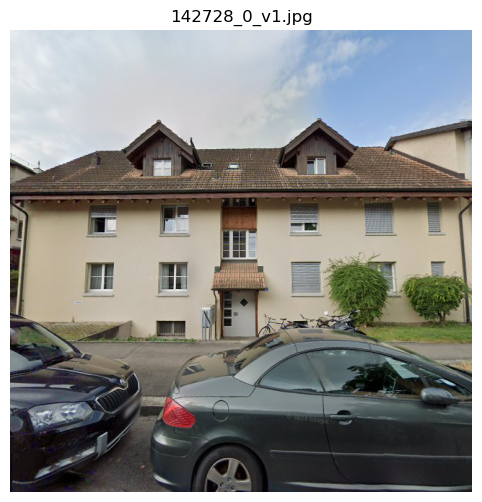

In [15]:
# -----------------------------------------------------------------------------
# Quick input preview
# -----------------------------------------------------------------------------

sample_image_path = image_paths[0]
print("Previewing:", sample_image_path.name)
show_image(sample_image_path)

In [16]:
# -----------------------------------------------------------------------------
# Extra imports used by the DUSt3R / GeoCalib processing pipeline
# -----------------------------------------------------------------------------

import glob
import time

import torch
import open3d as o3d
import plotly.graph_objects as go

print("Additional pipeline imports loaded.")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Additional pipeline imports loaded.


In [17]:
# -----------------------------------------------------------------------------
# Torch / CUDA environment check
# -----------------------------------------------------------------------------

use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")

print("torch version:", torch.__version__)
print("CUDA available:", use_cuda)
print("device:", device)

if use_cuda:
    print("CUDA version:", torch.version.cuda)
    print("GPU count:", torch.cuda.device_count())
    print("GPU name:", torch.cuda.get_device_name(0))

torch version: 2.5.1
CUDA available: True
device: cuda
CUDA version: 12.1
GPU count: 1
GPU name: NVIDIA GeForce RTX 4090


In [ ]:
# -----------------------------------------------------------------------------
# Add DUSt3R repository to Python path
# -----------------------------------------------------------------------------

if str(DUST3R_DIR) not in sys.path:
    sys.path.append(0, str(DUST3R_DIR))

print("DUSt3R path added:", DUST3R_DIR)

DUSt3R path added: D:\facade2dim\image2bipv\external\dust3r


In [19]:
# -----------------------------------------------------------------------------
# DUSt3R imports
# -----------------------------------------------------------------------------
# These imports assume the DUSt3R repository is available in external/dust3r
# -----------------------------------------------------------------------------

from dust3r.inference import inference
from dust3r.utils.image import load_images
from dust3r.image_pairs import make_pairs
from dust3r.cloud_opt import global_aligner, GlobalAlignerMode

print("DUSt3R imports loaded successfully.")

Warning, cannot find cuda-compiled version of RoPE2D, using a slow pytorch version instead
DUSt3R imports loaded successfully.


D:\facade2dim\image2bipv\external\dust3r\dust3r\cloud_opt\base_opt.py:299: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  @torch.cuda.amp.autocast(enabled=False)


In [24]:
# -----------------------------------------------------------------------------
# DUSt3R model loading
# -----------------------------------------------------------------------------
# We import the *correct* demo.py explicitly from external/dust3r/demo.py
# to avoid collisions with croco/demo.py or any other module named "demo".
# -----------------------------------------------------------------------------

import importlib.util

CHECKPOINTS_DIR = DUST3R_DIR / "checkpoints"
WEIGHTS_FILENAME = "DUSt3R_ViTLarge_BaseDecoder_512_dpt.pth"
WEIGHTS_PATH = CHECKPOINTS_DIR / WEIGHTS_FILENAME
DUST3R_DEMO_PATH = DUST3R_DIR / "demo.py"

if not WEIGHTS_PATH.exists():
    raise FileNotFoundError(
        f"DUSt3R weights not found: {WEIGHTS_PATH}\n"
        "Please download the checkpoint and place it under external/dust3r/checkpoints/."
    )

if not DUST3R_DEMO_PATH.exists():
    raise FileNotFoundError(
        f"DUSt3R demo.py not found: {DUST3R_DEMO_PATH}\n"
        "Please check that external/dust3r is the correct repository root."
    )

# Load external/dust3r/demo.py explicitly
spec = importlib.util.spec_from_file_location("dust3r_demo", DUST3R_DEMO_PATH)
dust3r_demo = importlib.util.module_from_spec(spec)
spec.loader.exec_module(dust3r_demo)

# Prevent notebook / Jupyter args from interfering with argparse
sys.argv = sys.argv[:1]

parser = dust3r_demo.get_args_parser()
args = parser.parse_args([])

# Force notebook-safe defaults
args.weights = str(WEIGHTS_PATH)
args.device = str(device)

model = dust3r_demo.load_model(args.weights, args.device)

print("Loaded DUSt3R model from:", WEIGHTS_PATH)
print("Loaded DUSt3R demo module from:", DUST3R_DEMO_PATH)

... loading model from D:\facade2dim\image2bipv\external\dust3r\checkpoints\DUSt3R_ViTLarge_BaseDecoder_512_dpt.pth


D:\facade2dim\image2bipv\external\dust3r\dust3r\inference.py:18: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(model_path, map_location='cpu')


instantiating : AsymmetricCroCo3DStereo(enc_depth=24, dec_depth=12, enc_embed_dim=1024, dec_embed_dim=768, enc_num_heads=16, dec_num_heads=12, pos_embed='RoPE100', patch_embed_cls='PatchEmbedDust3R', img_size=(512, 512), head_type='dpt', output_mode='pts3d', depth_mode=('exp', -inf, inf), conf_mode=('exp', 1, inf), landscape_only=False)
<All keys matched successfully>
Loaded DUSt3R model from: D:\facade2dim\image2bipv\external\dust3r\checkpoints\DUSt3R_ViTLarge_BaseDecoder_512_dpt.pth
Loaded DUSt3R demo module from: D:\facade2dim\image2bipv\external\dust3r\demo.py


In [21]:
# -----------------------------------------------------------------------------
# GeoCalib model
# -----------------------------------------------------------------------------

geocalib_model = GeoCalib(weights="pinhole").to(device)
print("GeoCalib model loaded on:", device)

GeoCalib model loaded on: cuda


In [25]:
# -----------------------------------------------------------------------------
# Reconstruction / alignment parameters
# -----------------------------------------------------------------------------

BATCH_SIZE = 1
NITER = 300
SCHEDULE = "cosine"
LR = 0.01

# Controls output size of the orthorectified image
GLOBAL_RATIO = 50.0
OUTPUT_SCALE_FACTOR = 50

# Whether to force single-view mode by duplicating the selected image
SINGLE_VIEW = False

print("Pipeline parameters initialized.")

Pipeline parameters initialized.


In [26]:
# -----------------------------------------------------------------------------
# Helper functions: filename parsing and orthorectification
# -----------------------------------------------------------------------------

def parse_id_and_version(filepath):
    """
    Extract the facade ID and version suffix from a filename.

    Example:
        'hKQx02KBJ4Rz8HgxxJwrCg_f0.jpg' -> ('hKQx02KBJ4Rz8HgxxJwrCg', 'f0')
    """
    filename = os.path.basename(filepath)
    name, _ = os.path.splitext(filename)
    idx = name.rfind("_")
    if idx == -1:
        return name, ""
    facade_id = name[:idx]
    version = name[idx + 1 :]
    return facade_id, version


def orthorectify_facade(
    src_img: np.ndarray,
    K: np.ndarray,
    Rt: np.ndarray,
    plane_origin: np.ndarray,
    plane_normal: np.ndarray,
    vertical_in_plane: np.ndarray,
    min_x: float,
    max_x: float,
    min_y: float,
    max_y: float,
    out_width: int,
    out_height: int,
):
    """
    Orthorectify a facade plane into a fronto-parallel view.
    """
    normal = plane_normal / (np.linalg.norm(plane_normal) + 1e-12)

    v_dir = vertical_in_plane - (np.dot(vertical_in_plane, normal) * normal)
    v_dir /= (np.linalg.norm(v_dir) + 1e-12)

    h_dir = np.cross(normal, v_dir)
    h_dir /= (np.linalg.norm(h_dir) + 1e-12)

    y_pix, x_pix = np.indices((out_height, out_width), dtype=np.float32)

    x_norm = x_pix / max(out_width - 1, 1)
    y_norm = y_pix / max(out_height - 1, 1)

    X_plane = min_x + x_norm * (max_x - min_x)
    Y_plane = min_y + y_norm * (max_y - min_y)

    X_plane_flat = X_plane.ravel()
    Y_plane_flat = Y_plane.ravel()

    pts_3d_world = (
        plane_origin[None, :]
        + X_plane_flat[:, None] * h_dir[None, :]
        + Y_plane_flat[:, None] * v_dir[None, :]
    )

    R = Rt[:, :3]
    t = Rt[:, 3]
    pts_3d_cam = pts_3d_world @ R.T + t

    fx, fy = K[0, 0], K[1, 1]
    cx, cy = K[0, 2], K[1, 2]

    x_cam = pts_3d_cam[:, 0]
    y_cam = pts_3d_cam[:, 1]
    z_cam = pts_3d_cam[:, 2] + 1e-12

    u_proj = fx * (x_cam / z_cam) + cx
    v_proj = fy * (y_cam / z_cam) + cy

    map_x = u_proj.reshape((out_height, out_width)).astype(np.float32)
    map_y = v_proj.reshape((out_height, out_width)).astype(np.float32)

    ortho_img = cv2.remap(
        src_img,
        map_x,
        map_y,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0),
    )

    return ortho_img

In [27]:
# -----------------------------------------------------------------------------
# Helper functions: Open3D point cloud utilities
# -----------------------------------------------------------------------------

def make_open3d_pointcloud(points, colors=None):
    """
    Create an Open3D point cloud from Nx3 points and optional Nx3 colors.
    """
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(points)

    if colors is not None:
        pcd.colors = o3d.utility.Vector3dVector(colors)

    return pcd


def save_open3d_screenshot_facade_view(
    geometry_list,
    out_path,
    plane_origin,
    normal,
    horizontal_in_plane,
    in_plane_vertical,
    width=1400,
    height=1000,
    point_size=3.0,
    bg_color=(1, 1, 1),
    zoom=0.7,
):
    """
    Save an Open3D screenshot using a facade-aware camera pose.
    """
    vis = o3d.visualization.Visualizer()
    vis.create_window(visible=False, width=width, height=height)

    for geom in geometry_list:
        vis.add_geometry(geom)

    render_opt = vis.get_render_option()
    render_opt.point_size = point_size
    render_opt.background_color = np.array(bg_color, dtype=np.float32)

    front = -0.85 * normal - 0.25 * horizontal_in_plane - 0.20 * in_plane_vertical
    front = front / (np.linalg.norm(front) + 1e-12)

    up = -in_plane_vertical / (np.linalg.norm(in_plane_vertical) + 1e-12)
    lookat = plane_origin

    ctr = vis.get_view_control()
    ctr.set_zoom(zoom)
    ctr.set_front(front.tolist())
    ctr.set_lookat(lookat.tolist())
    ctr.set_up(up.tolist())

    vis.poll_events()
    vis.update_renderer()
    vis.capture_screen_image(str(out_path))
    vis.destroy_window()

    print("Saved visualization:", out_path)

In [28]:
# -----------------------------------------------------------------------------
# Helper functions: RGB coloring and facade frame visualization
# -----------------------------------------------------------------------------

def build_rgb_colored_pointcloud_from_image(
    pts3d_view,
    mask_resized,
    image_bgr,
    facade_tint_strength=0.22,
    facade_color=(0.78, 0.28, 0.28),
    non_facade_gray_strength=0.55,
):
    """
    Build a point cloud with colors sampled from the image.

    Facade points are softly tinted.
    Non-facade points are softly blended toward grayscale.
    """
    H, W = pts3d_view.shape[:2]

    img_small_bgr = cv2.resize(image_bgr, (W, H), interpolation=cv2.INTER_LINEAR)
    img_small_rgb = cv2.cvtColor(img_small_bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

    points = pts3d_view.reshape(-1, 3)
    colors = img_small_rgb.reshape(-1, 3).copy()
    facade_mask = mask_resized.flatten().astype(bool)

    valid_mask = np.isfinite(points).all(axis=1)
    points_valid = points[valid_mask]
    colors_valid = colors[valid_mask]
    facade_mask_valid = facade_mask[valid_mask]

    if non_facade_gray_strength > 0:
        non_facade_mask = ~facade_mask_valid
        rgb_nf = colors_valid[non_facade_mask]
        gray_nf = rgb_nf.mean(axis=1, keepdims=True)
        gray_nf = np.repeat(gray_nf, 3, axis=1)

        colors_valid[non_facade_mask] = (
            (1.0 - non_facade_gray_strength) * rgb_nf
            + non_facade_gray_strength * gray_nf
        )

    if facade_tint_strength > 0:
        tint = np.array(facade_color, dtype=np.float32)[None, :]
        colors_valid[facade_mask_valid] = (
            (1.0 - facade_tint_strength) * colors_valid[facade_mask_valid]
            + facade_tint_strength * tint
        )

    colors_valid = np.clip(colors_valid, 0.0, 1.0)
    return points_valid, colors_valid, facade_mask_valid


def create_facade_orientation_geometry(
    plane_origin,
    horizontal_in_plane,
    in_plane_vertical,
    normal,
    gravity_world,
    facade_width,
    facade_height,
    axis_scale=0.35,
):
    """
    Create Open3D line geometry showing the facade local frame and gravity.

    Colors:
    - horizontal axis: red
    - vertical axis: blue
    - facade normal: green
    - gravity: dark gray
    """
    scale = axis_scale * max(facade_width, facade_height, 1e-6)

    h_end = plane_origin + scale * horizontal_in_plane
    v_end = plane_origin + scale * in_plane_vertical
    n_end = plane_origin + scale * normal
    g_end = plane_origin + scale * gravity_world

    points = np.array([
        plane_origin, h_end,
        plane_origin, v_end,
        plane_origin, n_end,
        plane_origin, g_end,
    ], dtype=np.float64)

    lines = [
        [0, 1],
        [2, 3],
        [4, 5],
        [6, 7],
    ]

    colors = np.array([
        [1.0, 0.0, 0.0],
        [0.0, 0.0, 1.0],
        [0.0, 0.7, 0.0],
        [0.2, 0.2, 0.2],
    ], dtype=np.float64)

    line_set = o3d.geometry.LineSet(
        points=o3d.utility.Vector3dVector(points),
        lines=o3d.utility.Vector2iVector(lines),
    )
    line_set.colors = o3d.utility.Vector3dVector(colors)

    return line_set

In [29]:
# -----------------------------------------------------------------------------
# Optional helper: interactive Plotly point cloud viewer
# -----------------------------------------------------------------------------

def show_interactive_rgb_facade_pointcloud(
    points,
    colors_rgb,
    plane_origin=None,
    normal=None,
    horizontal_in_plane=None,
    in_plane_vertical=None,
    title="Facade point cloud",
    point_size=2,
    camera_distance=2.2,
):
    """
    Show an interactive Plotly point cloud using already-colored RGB points.
    """
    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=points[:, 0],
        y=points[:, 1],
        z=points[:, 2],
        mode="markers",
        marker=dict(
            size=point_size,
            color=[
                f"rgb({int(255*r)},{int(255*g)},{int(255*b)})"
                for r, g, b in colors_rgb
            ],
            opacity=0.78
        ),
        name="Point cloud"
    ))

    layout_kwargs = dict(
        title=title,
        scene=dict(
            xaxis=dict(title="X", showbackground=True, backgroundcolor="lightgray"),
            yaxis=dict(title="Y", showbackground=True, backgroundcolor="lightgray"),
            zaxis=dict(title="Z", showbackground=True, backgroundcolor="lightgray"),
            aspectmode="data",
        ),
        width=950,
        height=750,
        margin=dict(l=0, r=0, b=0, t=40),
    )

    if (
        plane_origin is not None
        and normal is not None
        and horizontal_in_plane is not None
        and in_plane_vertical is not None
    ):
        front = -0.85 * normal - 0.25 * horizontal_in_plane - 0.20 * in_plane_vertical
        front = front / (np.linalg.norm(front) + 1e-12)
        up = -in_plane_vertical / (np.linalg.norm(in_plane_vertical) + 1e-12)

        eye = (-camera_distance * front).tolist()
        up_vec = up.tolist()

        layout_kwargs["scene"]["camera"] = dict(
            eye=dict(x=eye[0], y=eye[1], z=eye[2]),
            up=dict(x=up_vec[0], y=up_vec[1], z=up_vec[2]),
            center=dict(x=0, y=0, z=0),
        )

    fig.update_layout(**layout_kwargs)
    fig.show()

In [ ]:
# -----------------------------------------------------------------------------
# Metadata loading
# -----------------------------------------------------------------------------
# The notebook expects a metadata CSV that selects which facade view
# version should be used.
# -----------------------------------------------------------------------------

if not METADATA_CSV.exists():
    raise FileNotFoundError(
        f"Metadata CSV not found: {METADATA_CSV}\n"
        "This notebook expects metadata.csv to be present under data/demo/input/."
    )

# Try comma first, then semicolon if needed
try:
    df_selected = pd.read_csv(METADATA_CSV)
    if df_selected.shape[1] == 1:
        df_selected = pd.read_csv(METADATA_CSV, sep=";")
except Exception:
    df_selected = pd.read_csv(METADATA_CSV, sep=";")

print("Loaded metadata:", METADATA_CSV)
display(df_selected.head())

has_facade_id = "facade_id" in df_selected.columns
has_EGID_EDID = "EGID" in df_selected.columns and "EDID" in df_selected.columns

if has_facade_id:
    csv_version = {
        str(r.facade_id): str(r.version).strip()
        for _, r in df_selected.iterrows()
    }
elif has_EGID_EDID:
    csv_version = {
        (str(r.EGID), str(r.EDID)): str(r.version).strip()
        for _, r in df_selected.iterrows()
    }
else:
    raise ValueError(
        "metadata.csv must contain either 'facade_id' or both 'EGID' and 'EDID'."
    )

print("Metadata lookup prepared.")

Loaded metadata: D:\facade2dim\image2bipv\data\demo\input\metadata.csv


,Unnamed: 0,index,SQLindex,EGID,EDID,EGAID,GGDENR,GGDENAME,GBAUJ,GAREA,GASTW,GEBF,GKLAS,address,DKOD,DKOD_wgs,GKOD,GKOD_wgs,be_overlap,street_and_number,gsv_status,gsv_wgs,gsv_src,gsv_date,building_pt,entrance_pt,gsv_pt,view_line,view_line_length,geometry_sf,geometry_block,block_height,e_to_sf,e_to_block,base_geometry_src,facade_pt,facade_distance,geometry,filter_src,filter_dist,filter_year,filter_height,filter_all,pitch_1,pitch_x,heading,floors_seen,height_block_acc,width_acc,new_imgs_for_w_acc,drop,version,retake,notes,Unnamed: 53,Unnamed: 54,Unnamed: 55
0,336.0,101.0,101,149099,0,100124126,261,ZÃ¼rich,1971,172,9,1548,1122,"Brauerstrasse 31, 8004 ZÃ¼rich","('2682193.621', '1247993.666')","(47.377651336316504, 8.527012640395744)","('2682194.12', '1247992.421')","(47.37764007730887, 8.527019018540532)",False,Brauerstrasse 31,OK,"(47.3777704129046, 8.527135085401419)",Â© Google,01.09.2024,POINT (2682194.1206169124 1247992.4221392379),POINT (2682193.621616911 1247993.6671392377),POINT (2682202.6842748434 1248007.0333190532),LINESTRING (2682202.6842748434 1248007.0333190...,16.148886,POLYGON ((2682193.1142980177 1248001.900354660...,POLYGON ((2682193.2118274304 1248001.731940449...,20.4,1.231431,1.327520,BLOCK,POINT (2682197.1213658983 1247998.8287898945),9.912631,POLYGON ((2682193.2118274304 1248001.731940449...,True,True,True,True,True,32.231787,39.769646,214.138410,7.5,0.0,1.0,1,NaN,1,NaN,NaN,"https://www.google.com/maps/@47.377775,8.52714...","https://www.google.com/maps/@47.3778288,8.5270...","https://www.google.com/maps/@47.3777217,8.5272..."
1,343.0,79.0,79,151360,0,100144443,261,ZÃ¼rich,1976,164,4,656,1122,"BrÃ¼derhofweg 31, 8057 ZÃ¼rich","('2683045.647', '1250516.67')","(47.40023471391282, 8.538761834650565)","('2683045.753', '1250516.865')","(47.400236454240805, 8.538763274902157)",False,BrÃ¼derhofweg 31,OK,"(47.40029725318168, 8.538956434954304)",Â© Google,01.06.2022,POINT (2683045.7536167996 1250516.866139768),POINT (2683045.6476167995 1250516.6711397637),POINT (2683060.2388803815 1250523.829718847),LINESTRING (2683060.2388803815 1250523.8297188...,16.252699,"POLYGON ((2683042.469244732 1250506.954625113,...",POLYGON ((2683054.7076358977 1250515.043730683...,12.1,0.654904,0.258812,BLOCK,POINT (2683051.6690003406 1250519.6252739294),9.545690,POLYGON ((2683054.7076358977 1250515.043730683...,True,True,True,True,True,9.903944,21.012656,243.867098,3.5,0.0,1.0,1,NaN,1,NaN,NaN,"https://www.google.com/maps/@47.400297,8.53895...","https://www.google.com/maps/@47.4002216,8.5390...","https://www.google.com/maps/@47.4003753,8.5388..."
2,358.0,104.0,104,142728,0,100124972,261,ZÃ¼rich,1988,220,5,1100,1122,"Speerstrasse 4, 8038 ZÃ¼rich","('2682103.396', '1244176.397')","(47.3433322392964, 8.525118248831385)","('2682103.761', '1244176.697')","(47.34333489188743, 8.525123133303147)",False,Speerstrasse 4,OK,"(47.34343397894494, 8.525316539321336)",Â© Google,01.07.2022,POINT (2682103.7616180223 1244176.698138053),POINT (2682103.3966180226 1244176.3981380512),POINT (2682118.2233168026 1244187.9160561743),LINESTRING (2682118.2233168026 1244187.9160561...,18.774809,POLYGON ((2682092.723288553 1244181.2700536272...,POLYGON ((2682091.7274328237 1244182.652825318...,8.3,0.114454,0.947755,BLOCK,POINT (2682108.0954053085 1244180.0483266765),12.824810,POLYGON ((2682091.7274328237 1244182.652825318...,True,True,True,True,True,11.388829,19.665884,232.158641,2.5,0.0,1.0,1,NaN,1,NaN,height is tricky,"https://www.google.com/maps/@47.3434273,8.5253...","https://www.google.com/maps/@47.3434987,8.5252...","https://www.google.com/maps/@47.3433561,8.5253..."
3,363.0,23.0,23,302019911,0,101727623,261,ZÃ¼rich,2004,2420,7,16940,1122,"BÃ¼hlstrasse 47, 8055 ZÃ¼rich","('2681204.963', '1246607.163')","(47.36530451906434, 8.51367122168684)","('2681216.036', '1246590.97')","(47.36515752390656, 8.51381485813718)",False,BÃ¼hlstrasse 47,OK,"(47.3654367348581, 8.513398971817496)",Â© Google,01.09.2024,POINT (2681216.0366165726 1246590.9711390964),POINT (2681204.963616

Metadata lookup prepared.


In [31]:
# -----------------------------------------------------------------------------
# Group images by facade ID
# -----------------------------------------------------------------------------

all_img_paths = sorted(
    [str(p) for p in IMAGES_DIR.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
)

facade_groups = {}
for img_path in all_img_paths:
    facade_id, version = parse_id_and_version(img_path)
    facade_groups.setdefault(facade_id, []).append(img_path)

print(f"Found {len(facade_groups)} facade group(s).")

Found 18 facade group(s).


In [32]:
# -----------------------------------------------------------------------------
# Main processing loop
# -----------------------------------------------------------------------------
# For each facade group:
# 1. choose the requested view from metadata
# 2. load the corresponding mask
# 3. run DUSt3R reconstruction
# 4. estimate gravity with GeoCalib
# 5. fit a facade plane
# 6. compute a gravity-aligned facade frame
# 7. orthorectify the facade
# 8. save outputs and append a CSV row
# -----------------------------------------------------------------------------

last_points = None
last_colors_rgb = None
last_facade_name = None
last_plane_origin = None
last_normal = None
last_horizontal_in_plane = None
last_in_plane_vertical = None

for facade_id, img_paths in facade_groups.items():
    start_total = time.perf_counter()
    EGID = None

    # -------------------------------------------------------------------------
    # Determine desired version from metadata
    # -------------------------------------------------------------------------
    if has_facade_id:
        raw = csv_version.get(facade_id)
    else:
        EGID, EDID = facade_id.split("_")
        EGID = str(int(EGID))
        EDID = str(int(EDID))
        raw = csv_version.get((EGID, EDID))

    if pd.isna(raw) or raw is None:
        ver_num = "1"
    else:
        ver_num = str(int(float(raw)))

    desired_version = f"v{ver_num}"

    img_paths = sorted(img_paths)
    selected_img_path = None
    facade_view_idx = None

    for i, path in enumerate(img_paths):
        _, ver = parse_id_and_version(path)
        if ver == desired_version:
            selected_img_path = path
            facade_view_idx = i
            break

    if selected_img_path is None:
        selected_img_path = img_paths[0]
        facade_view_idx = 0
        _, desired_version = parse_id_and_version(selected_img_path)

    if SINGLE_VIEW:
        img_paths = [selected_img_path, selected_img_path]
        facade_view_idx = 0

    print(
        f"▶ {facade_id}: using {os.path.basename(selected_img_path)} "
        f"(mode = {'single' if SINGLE_VIEW else 'multi'})"
    )

    # -------------------------------------------------------------------------
    # Load corresponding facade mask
    # -------------------------------------------------------------------------
    mask_name = Path(selected_img_path).stem + ".png"
    selected_mask_path = MASKS_DIR / mask_name

    if not selected_mask_path.exists():
        print(f"Mask file not found for {selected_img_path}. Skipping.")
        continue

    mask = cv2.imread(str(selected_mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        print(f"Could not load mask: {selected_mask_path}. Skipping.")
        continue

    mask_binary = (mask > 0).astype(np.uint8)

    # -------------------------------------------------------------------------
    # DUSt3R inference
    # -------------------------------------------------------------------------
    images = load_images(img_paths, size=640, square_ok=True)
    pairs = make_pairs(images, scene_graph="complete", prefilter=None, symmetrize=True)

    if len(pairs) == 0:
        print(f"No valid pairs for {facade_id}. Skipping.")
        continue

    outputs = inference(pairs, model, device, batch_size=BATCH_SIZE)

    try:
        scene = None
        for pair_out in (outputs if isinstance(outputs, list) else [outputs]):
            sub = global_aligner(
                pair_out,
                device=device,
                mode=GlobalAlignerMode.PointCloudOptimizer
            )
            sub.compute_global_alignment(
                init="mst",
                niter=NITER,
                schedule=SCHEDULE,
                lr=LR
            )
            scene = sub if scene is None else scene.merge(sub)

    except (cv2.error, ValueError) as e:
        print(f"Skipping facade {facade_id} due to alignment error: {e}")
        continue

    poses = scene.get_im_poses()
    pts3d_list = scene.get_pts3d()
    Ks_all = scene.get_intrinsics()

    # -------------------------------------------------------------------------
    # GeoCalib gravity estimation
    # -------------------------------------------------------------------------
    geo_img = geocalib_model.load_image(selected_img_path).to(device)
    geo_results = geocalib_model.calibrate(geo_img)
    gravity_vector = geo_results["gravity"][0].cpu().numpy()

    # -------------------------------------------------------------------------
    # Select the target view and resize mask to match DUSt3R output grid
    # -------------------------------------------------------------------------
    pts3d_view = pts3d_list[facade_view_idx].detach().cpu().numpy()
    H_in, W_in = pts3d_view.shape[:2]

    mask_resized = cv2.resize(mask_binary, (W_in, H_in), interpolation=cv2.INTER_NEAREST)
    pts3d_flat = pts3d_view.reshape(-1, 3)

    K_base = Ks_all[facade_view_idx].detach().cpu().numpy()

    hi_res_img = cv2.imread(selected_img_path)
    H_orig, W_orig = hi_res_img.shape[:2]

    sx = W_orig / W_in
    sy = H_orig / H_in

    K_scaled = K_base.copy()
    K_scaled[0, 0] *= sx
    K_scaled[0, 2] *= sx
    K_scaled[1, 1] *= sy
    K_scaled[1, 2] *= sy

    pose_cw = poses[facade_view_idx]
    if isinstance(pose_cw, torch.Tensor):
        pose_cw = pose_cw.detach().cpu().numpy()

    R_cw = pose_cw[:3, :3]
    t_cw = pose_cw[:3, 3]

    R_wc = R_cw.T
    t_wc = -R_wc @ t_cw
    Rt = np.hstack([R_wc, t_wc[:, None]])

    gravity_cam = gravity_vector / (np.linalg.norm(gravity_vector) + 1e-12)
    gravity_world = R_cw @ gravity_cam
    gravity_world /= (np.linalg.norm(gravity_world) + 1e-12)

    mask_flat = mask_resized.flatten().astype(bool)
    facade_pts = pts3d_flat[mask_flat]

    if facade_pts.shape[0] == 0:
        print("No facade points after masking. Skipping.")
        continue

    # -------------------------------------------------------------------------
    # Build colored point cloud for diagnostics
    # -------------------------------------------------------------------------
    pts_all_valid, pcd_colors_rgb, facade_mask_valid = build_rgb_colored_pointcloud_from_image(
        pts3d_view,
        mask_resized,
        hi_res_img,
        facade_tint_strength=0.22,
        non_facade_gray_strength=0.55,
        facade_color=(0.78, 0.28, 0.28),
    )

    pcd_full_rgb = make_open3d_pointcloud(pts_all_valid, pcd_colors_rgb)

    pcd_ply_path = POINTCLOUD_DIR / f"{facade_id}_{desired_version}_rgb_tinted_pcd.ply"
    o3d.io.write_point_cloud(str(pcd_ply_path), pcd_full_rgb)

    # -------------------------------------------------------------------------
    # Plane segmentation on the masked facade points
    # -------------------------------------------------------------------------
    pcd_facade = o3d.geometry.PointCloud()
    pcd_facade.points = o3d.utility.Vector3dVector(facade_pts)

    plane_model, inliers = pcd_facade.segment_plane(
        distance_threshold=0.01,
        ransac_n=3,
        num_iterations=1000
    )

    a, b, c, d = plane_model
    normal = np.array([a, b, c], dtype=np.float64)
    normal /= np.linalg.norm(normal)

    pcd_plane = pcd_facade.select_by_index(inliers)
    pcd_plane_np = np.asarray(pcd_plane.points)

    def project_point_to_plane(p, plane_normal, plane_d):
        return p - (np.dot(p, plane_normal) + plane_d) * plane_normal

    projected_points = np.array(
        [project_point_to_plane(p, normal, d) for p in pcd_plane_np]
    )

    # -------------------------------------------------------------------------
    # Gravity-aligned facade basis
    # -------------------------------------------------------------------------
    g = gravity_world
    v_raw = g - (g @ normal) * normal
    norm_v = np.linalg.norm(v_raw)

    if norm_v < 1e-6:
        cand_axes = [
            np.array([1.0, 0.0, 0.0]),
            np.array([0.0, 1.0, 0.0]),
            np.array([0.0, 0.0, 1.0]),
        ]
        ref = min(cand_axes, key=lambda a: abs(a @ normal))
        v_raw = np.cross(normal, ref)
        norm_v = np.linalg.norm(v_raw)

    in_plane_vertical = v_raw / norm_v

    if in_plane_vertical[1] < 0:
        in_plane_vertical = -in_plane_vertical

    horizontal_in_plane = np.cross(normal, in_plane_vertical)
    horizontal_in_plane /= (np.linalg.norm(horizontal_in_plane) + 1e-12)

    plane_origin = projected_points.mean(axis=0)

    pts_2d = []
    for p in projected_points:
        vec = p - plane_origin
        x = np.dot(vec, horizontal_in_plane)
        y = np.dot(vec, in_plane_vertical)
        pts_2d.append([x, y])

    pts_2d = np.array(pts_2d)
    min_x, min_y = pts_2d.min(axis=0)
    max_x, max_y = pts_2d.max(axis=0)

    facade_width = max_x - min_x
    facade_height = max_y - min_y

    # -------------------------------------------------------------------------
    # Visualization geometries
    # -------------------------------------------------------------------------
    orientation_line_set = create_facade_orientation_geometry(
        plane_origin=plane_origin,
        horizontal_in_plane=horizontal_in_plane,
        in_plane_vertical=in_plane_vertical,
        normal=normal,
        gravity_world=gravity_world,
        facade_width=facade_width,
        facade_height=facade_height,
        axis_scale=0.35,
    )

    corners_3d = []
    for (x, y) in [(min_x, min_y), (max_x, min_y), (max_x, max_y), (min_x, max_y)]:
        corner_3d = plane_origin + x * horizontal_in_plane + y * in_plane_vertical
        corners_3d.append(corner_3d)
    corners_3d = np.array(corners_3d)

    lines = [[0, 1], [1, 2], [2, 3], [3, 0]]
    line_set = o3d.geometry.LineSet(
        points=o3d.utility.Vector3dVector(corners_3d),
        lines=o3d.utility.Vector2iVector(lines)
    )
    line_set.colors = o3d.utility.Vector3dVector([[0, 1, 0]] * len(lines))

    pcd_vis_path = PLOTS_DIR / f"{facade_id}_{desired_version}_pcd_rgb_tinted.png"
    save_open3d_screenshot_facade_view(
        [pcd_full_rgb, line_set, orientation_line_set],
        pcd_vis_path,
        plane_origin=plane_origin,
        normal=normal,
        horizontal_in_plane=horizontal_in_plane,
        in_plane_vertical=in_plane_vertical,
        point_size=2.5,
        zoom=0.7,
    )

    # Save last successful facade for optional interactive preview
    last_points = pts_all_valid
    last_colors_rgb = pcd_colors_rgb
    last_facade_name = f"{facade_id}_{desired_version}"
    last_plane_origin = plane_origin.copy()
    last_normal = normal.copy()
    last_horizontal_in_plane = horizontal_in_plane.copy()
    last_in_plane_vertical = in_plane_vertical.copy()

    # -------------------------------------------------------------------------
    # Orthorectification
    # -------------------------------------------------------------------------
    corrected_width = facade_width * GLOBAL_RATIO
    corrected_height = facade_height * GLOBAL_RATIO

    W_pred = max(int(round(corrected_width * OUTPUT_SCALE_FACTOR)), 1)
    H_pred = max(int(round(corrected_height * OUTPUT_SCALE_FACTOR)), 1)

    ortho_img = orthorectify_facade(
        hi_res_img,
        K_scaled,
        Rt,
        plane_origin,
        normal,
        in_plane_vertical,
        min_x,
        max_x,
        min_y,
        max_y,
        W_pred,
        H_pred,
    )

    out_rect_path = RECTIFIED_DIR / f"{facade_id}_{desired_version}_rectified.png"
    cv2.imwrite(str(out_rect_path), ortho_img)

    # Side-by-side visualization
    fig, axs = plt.subplots(1, 2, figsize=(10, 5))
    axs[0].imshow(hi_res_img[:, :, ::-1])
    axs[0].set_title(f"{facade_id} - Original")
    axs[0].axis("off")

    axs[1].imshow(ortho_img[:, :, ::-1])
    axs[1].set_title(f"{facade_id} - Orthorectified")
    axs[1].axis("off")

    plt.tight_layout()

    viz_path = PLOTS_DIR / f"{facade_id}_{desired_version}_comparison.png"
    plt.savefig(viz_path, dpi=300, bbox_inches="tight")
    plt.close()

    # -------------------------------------------------------------------------
    # Append structured results to CSV
    # -------------------------------------------------------------------------
    if use_cuda:
        torch.cuda.synchronize()

    runtime_s = time.perf_counter() - start_total

    def flat(m):
        return m.astype(float).reshape(-1).tolist()

    row_dict = {
        "facade_id": facade_id,
        "facade_version": desired_version,
        "selected_image": os.path.basename(selected_img_path),
        "mask_file": mask_name,

        **{
            f"K{i}{j}": val
            for (i, j), val in zip(
                [(1,1),(1,2),(1,3),(2,1),(2,2),(2,3),(3,1),(3,2),(3,3)],
                flat(K_scaled)
            )
        },

        **{
            f"Rt{i}{j}": val
            for (i, j), val in zip(
                [
                    (1,1),(1,2),(1,3),(1,4),
                    (2,1),(2,2),(2,3),(2,4),
                    (3,1),(3,2),(3,3),(3,4),
                ],
                flat(Rt)
            )
        },

        "po_x": plane_origin[0],
        "po_y": plane_origin[1],
        "po_z": plane_origin[2],
        "h_x": horizontal_in_plane[0],
        "h_y": horizontal_in_plane[1],
        "h_z": horizontal_in_plane[2],
        "v_x": in_plane_vertical[0],
        "v_y": in_plane_vertical[1],
        "v_z": in_plane_vertical[2],
        "normal_x": normal[0],
        "normal_y": normal[1],
        "normal_z": normal[2],
        "gravity_x": gravity_world[0],
        "gravity_y": gravity_world[1],
        "gravity_z": gravity_world[2],
        "min_x": min_x,
        "max_x": max_x,
        "min_y": min_y,
        "max_y": max_y,
        "W_pred": W_pred,
        "H_pred": H_pred,
        "H_orig": H_orig,
        "W_orig": W_orig,
        "predicted_width": facade_width,
        "predicted_height": facade_height,
        "rectified_image": out_rect_path.name,
        "comparison_plot": viz_path.name,
        "pointcloud_file": pcd_ply_path.name,
        "runtime_s": runtime_s,
    }

    df_new = pd.DataFrame([row_dict])

    if not RESULTS_CSV.exists():
        df_new.to_csv(RESULTS_CSV, index=False)
    else:
        df_new.to_csv(RESULTS_CSV, mode="a", index=False, header=False)

    print(f"Saved rectified image: {out_rect_path}")
    print(f"Appended results to: {RESULTS_CSV}")
    print("Done with this facade.\n")

▶ 142728_0: using 142728_0_v1.jpg (mode = multi)
>> Loading a list of 3 images
 - adding D:\facade2dim\image2bipv\data\demo\input\images\142728_0_v1.jpg with resolution 640x640 --> 640x640
 - adding D:\facade2dim\image2bipv\data\demo\input\images\142728_0_v2.jpg with resolution 640x640 --> 640x640
 - adding D:\facade2dim\image2bipv\data\demo\input\images\142728_0_v3.jpg with resolution 640x640 --> 640x640
 (Found 3 images)
>> Inference with model on 6 image pairs


  0%|          | 0/6 [00:00<?, ?it/s]D:\facade2dim\image2bipv\external\dust3r\dust3r\inference.py:63: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=bool(use_amp)):
D:\facade2dim\image2bipv\external\dust3r\dust3r\model.py:161: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
D:\facade2dim\image2bipv\external\dust3r\dust3r\inference.py:67: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):
100%|██████████| 6/6 [00:02<00:00,  2.84it/s]


 init edge (1*,2*) score=20.338581085205078
 init edge (1,0*) score=18.83944320678711
 init loss = 0.01769832894206047
Global alignement - optimizing for:
['pw_poses', 'im_depthmaps', 'im_poses', 'im_focals', 'im_conf.0', 'im_conf.1', 'im_conf.2']


100%|██████████| 300/300 [00:09<00:00, 32.98it/s, lr=0.01 loss=0.00778367]


Saved visualization: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\plots\142728_0_v1_pcd_rgb_tinted.png
Saved rectified image: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\rectified\142728_0_v1_rectified.png
Appended results to: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\tables\dust3r_rectification_results.csv
Done with this facade.

▶ 142767_0: using 142767_0_v1.jpg (mode = multi)
>> Loading a list of 3 images
 - adding D:\facade2dim\image2bipv\data\demo\input\images\142767_0_v1.jpg with resolution 640x640 --> 640x640
 - adding D:\facade2dim\image2bipv\data\demo\input\images\142767_0_v2.jpg with resolution 640x640 --> 640x640
 - adding D:\facade2dim\image2bipv\data\demo\input\images\142767_0_v3.jpg with resolution 640x640 --> 640x640
 (Found 3 images)
>> Inference with model on 6 image pairs


...

Saved visualization: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\plots\302064053_0_v1_pcd_rgb_tinted.png
Saved rectified image: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\rectified\302064053_0_v1_rectified.png
Appended results to: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\tables\dust3r_rectification_results.csv
Done with this facade.

▶ 302065471_0: using 302065471_0_v2.jpg (mode = multi)
>> Loading a list of 2 images
 - adding D:\facade2dim\image2bipv\data\demo\input\images\302065471_0_v1.jpg with resolution 640x640 --> 640x640
 - adding D:\facade2dim\image2bipv\data\demo\input\images\302065471_0_v2.jpg with resolution 640x640 --> 640x640
 (Found 2 images)
>> Inference with model on 2 image pairs


100%|██████████| 2/2 [00:00<00:00,  2.96it/s]


 init edge (0*,1*) score=12.931122779846191
 init loss = 0.009921234101057053
Global alignement - optimizing for:
['pw_poses', 'im_depthmaps', 'im_poses', 'im_focals', 'im_conf.0', 'im_conf.1']


100%|██████████| 300/300 [00:08<00:00, 34.41it/s, lr=0.01 loss=0.0051251] 


Saved visualization: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\plots\302065471_0_v2_pcd_rgb_tinted.png
Saved rectified image: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\rectified\302065471_0_v2_rectified.png
Appended results to: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\tables\dust3r_rectification_results.csv
Done with this facade.



In [33]:
# -----------------------------------------------------------------------------
# Optional interactive inspection of the last successfully processed facade
# -----------------------------------------------------------------------------

if last_points is not None:
    show_interactive_rgb_facade_pointcloud(
        last_points,
        last_colors_rgb,
        plane_origin=last_plane_origin,
        normal=last_normal,
        horizontal_in_plane=last_horizontal_in_plane,
        in_plane_vertical=last_in_plane_vertical,
        title=f"Interactive 3D view: {last_facade_name}",
        point_size=2,
        camera_distance=1.2,
    )
else:
    print("No successful facade processed yet, so there is nothing to preview.")

In [34]:
# -----------------------------------------------------------------------------
# Quick check of the saved results table
# -----------------------------------------------------------------------------

if RESULTS_CSV.exists():
    results_df = pd.read_csv(RESULTS_CSV)
    print(f"Loaded results table with {len(results_df)} row(s).")
    display(results_df.head())
else:
    print("No results CSV found yet.")

Loaded results table with 18 row(s).


,facade_id,facade_version,selected_image,mask_file,K11,K12,K13,K21,K22,K23,K31,K32,K33,Rt11,Rt12,Rt13,Rt14,Rt21,Rt22,Rt23,Rt24,Rt31,Rt32,Rt33,Rt34,po_x,po_y,po_z,h_x,h_y,h_z,v_x,v_y,v_z,normal_x,normal_y,normal_z,gravity_x,gravity_y,gravity_z,min_x,max_x,min_y,max_y,W_pred,H_pred,H_orig,W_orig,predicted_width,predicted_height,rectified_image,comparison_plot,pointcloud_file,runtime_s
0,142728_0,v1,142728_0_v1.jpg,142728_0_v1.png,405.183746,0.0,320.0,0.0,405.183746,320.0,0.0,0.0,1.0,0.853899,-0.036141,-0.519182,0.182249,0.056741,0.998104,0.023843,-0.003079,0.517336,-0.049818,0.854331,0.000146,-0.059556,-0.000280,0.267655,-0.844631,0.033876,0.534275,0.004364,0.998398,-0.056405,0.535330,0.045310,0.843427,0.002316,-0.997755,0.066925,-0.163742,0.152957,-0.041035,0.052476,792,234,640,640,0.316699,0.093511,142728_0_v1_rectified.png,142728_0_v1_comparison.png,142728_0_v1_rgb_tinted_pcd.ply,14.662085
1,142767_0,v1,142767_0_v1.jpg,142767_0_v1.png,388.484222,0.0,320.0,0.0,388.484222,320.0,0.0,0.0,1.0,0.999802,0.011490,-0.016267,0.000000,-0.011245,0.999823,0.015113,0.000000,0.016438,-0.014927,0.999754,0.000000,0.007141,-0.032810,0.164005,-0.993846,-0.014222,0.109851,-0.016024,0.999751,-0.015542,0.109603,0.017207,0.993827,0.020125,-0.998401,0.052819,-0.107609,0.155638,-0.040362,0.072742,658,283,640,640,0.263247,0.113104,142767_0_v1_rectified.png,142767_0_v1_comparison.png,142767_0_v1_rgb_tinted_pcd.ply,12.861162
2,147978_0,v1,147978_0_v1.jpg,147978_0_v1.png,333.737488,0.0,320.0,0.0,333.737488,320.0,0.0,0.0,1.0,0.894083,-0.172214,-0.413471,0.197776,0.162903,0.984937,-0.057974,-0.001978,0.417227,-0.015522,0.908670,0.000062,-0.101016,-0.013845,0.235024,-0.892920,0.173869,0.415287,-0.009390,0.915026,-0.403285,0.450118,0.364001,0.815413,0.009022,-0.915323,0.402619,-0.102327,0.090999,-0.139500,0.133211,483,682,640,640,0.193327,0.272711,147978_0_v1_rectified.png,147978_0_v1_comparison.png,147978_0_v1_rgb_tinted_pcd.ply,13.488710
3,148455_0,v2,148455_0_v2.jpg,148455_0_v2.png,324.564423,0.0,320.0,0.0,324.564423,320.0,0.0,0.0,1.0,0.999958,0.007858,-0.004767,0.000000,-0.007939,0.999822,-0.017096,0.000000,0.004632,0.017133,0.999842,0.000000,-0.065266,-0.024020,0.212733,-0.991448,0.050170,0.120472,-0.004821,0.908438,-0.417991,0.130412,0.414997,0.900428,0.008916,-0.894951,0.446075,-0.111845,0.139693,-0.207703,0.146754,629,886,640,640,0.251538,0.354457,148455_0_v2_rectified.png,148455_0_v2_comparison.png,148455_0_v2_rgb_tinted_pcd.ply,12.383121
4,149099_0,v1,149099_0_v1.jpg,149099_0_v1.png,331.334930,0.0,320.0,0.0,331.334930,320.0,0.0,0.0,1.0,0.926754,0.169822,0.335093,-0.176860,-0.135516,0.983059,-0.123413,0.000008,-0.350375,0.068963,0.934067,0.006539,0.070722,0.015402,0.231891,-0.926539,-0.162747,-0.339173,0.005614,0.895499,-0.445028,-0.376156,0.414240,0.828802,-0.018166,-0.881174,0.472443,-0.111592,0.115923,-0.212582,0.127575,569,850,640,640,0.227515,0.340158,149099_0_v1_rectified.png,149099_0_v1_comparison.png,149099_0_v1_rgb_tinted_pcd.ply,14.189045
